# 02 — Building an ML-ready dataset from raw OpenSky data

**Project:** predicting the remaining flight time of commercial flights from their ADS-B state vectors (position, speed, altitude…).

**Goal of this notebook:** turn one day of raw OpenSky data into a clean, balanced training dataset of about 2 million state vectors, each labelled with the time left before arrival.

**Data.** One full UTC day (2026-03-01): the dataset *Complete One Day Trino Tables Snapshot (March 2026)* from the [public datasets of the OpenSky Network](https://opensky-network.org/data/scientific#d11), exports of its historical database (whose direct access through Trino is reserved to researchers):
- `state_vectors_data4`: one row per tracked aircraft and per second (position, velocities, barometric and geometric altitudes). 24 hourly parquet files, several hundred million rows, ~12 GB.
- `flights_data4`: one row per flight (`icao24`, `firstSeen`, `lastSeen`, estimated departure and arrival airports).

**Pipeline.** Every step reads its input from disk and writes its output to `data/processed/`:

| Section | Step | Output | Content |
|---|---|---|---|
| 2 | Matching | `matched/` | airborne state vectors linked to a flight, with a first `remaining_time` label |
| 3 | Cleaning | `clean/` | altitude outliers and physically impossible values removed |
| 4 | Flight selection | `ifr/` | commercial-like (IFR) flights only |
| 5 | Flight phases | `phases/`, `cruise_info.parquet` | `phase_of_flight` column (climb / cruise / descent) |
| 6 | Sampling | `ml/ml_dataset.parquet` | 60 state vectors per flight, final label |

**Constraints.** The raw data does not fit in memory, so everything is processed file by file and batch by batch, and only small per-flight aggregates are kept in memory.

**How to run.** The raw files are not versioned: they must be placed in `data/raw/state_vectors/` and `data/raw/flights/`. A full run can be quite long. Set `N_FILES = 2` in the setup cell for a quick dry run on two hourly files. After the setup cell, the notebook can be resumed at any of the sections 3 to 6, since each of them reads its input from disk.

## 0. Setup

The paths, the pipeline parameters (justified in the corresponding sections) and the helpers reused by several notebooks are in the package `src/opensky_eta`:
- `config.py`: paths, units, identifiers and parameters;
- `storage.py`: reading and writing the hourly parquet files;
- `cleaning.py`: flight statistics and the altitude cleaning functions of section 3;
- `dataset.py`: the processing steps of sections 2 to 6 (matching, cleaning, flight selection, phases, sampling), called below. The same functions build the whole dataset in one command: `python -m opensky_eta.dataset`.

The plot helpers specific to this notebook are defined below.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

from opensky_eta.cleaning import compute_flight_stats
from opensky_eta.config import (
    ALTITUDE_CEILING_FT, CLEAN_DIR, CRUISE_INFO_PATH, FLIGHT_KEY, IFR_DIR, LEVEL_VZ_FT_MIN,
    MATCHED_DIR, MAX_APPARENT_VZ_FT_MIN, MAX_CRUISE_GAP_FT, MAX_DURATION_H, MAX_SPEED_KT,
    MAX_VERTICAL_RATE_FT_MIN, MIN_ALTITUDE_FT, MIN_CRUISE_SPEED_KT, MIN_DURATION_MIN,
    MIN_JUMP_FT, MIN_MAX_ALTITUDE_FT, ML_DATASET_PATH, MS_TO_FT_MIN, MS_TO_KT, M_TO_FT, PHASES,
    PHASES_DIR, PHASE_TO_SEGMENT, PROJECT_DIR, RAW_STATE_VECTORS_DIR,
)
from opensky_eta.dataset import (
    check_ml_dataset, clean_state_vectors, ifr_criteria, label_phases, load_flights,
    make_flights_lookup, match_state_vectors, sample_ml_dataset, write_ifr_flights,
)
from opensky_eta.plotting import PHASE_COLORS, set_plot_style
from opensky_eta.storage import file_time_range, list_parquet_files, read_flight, to_utc

N_FILES = None  # e.g. 2 for a quick dry run on two hourly files

set_plot_style()


# ------------------------------------------------------------------
# Plot helpers of this notebook
# ------------------------------------------------------------------
def plot_altitude_vs_speed(flight_stats, ax, title):
    """Scatter plot of max altitude vs cruise speed, one point per flight."""
    ax.scatter(
        flight_stats["max_altitude_ft"], flight_stats["cruise_speed_kt"],
        s=2, alpha=0.3,
    )
    ax.set_xlabel("Max barometric altitude (ft)")
    ax.set_ylabel("Cruise speed (kt)")
    ax.set_title(title)


def plot_altitude_profiles(directory, flights, columns=("baroAltitude",), title=None):
    """Altitude vs time for a few flights (one subplot per flight)."""
    n_cols = min(len(flights), 3)
    n_rows = int(np.ceil(len(flights) / n_cols))
    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=(5 * n_cols, 3.2 * n_rows), squeeze=False
    )
    for ax, (_, flight) in zip(axes.ravel(), flights.iterrows()):
        trajectory = read_flight(directory, flight, ["time", *columns])
        minutes = (trajectory["time"] - trajectory["time"].iloc[0]) / 60
        for column in columns:
            ax.plot(minutes, trajectory[column] * M_TO_FT, linewidth=1, label=column)
        ax.set_title(f"{flight['icao24']}, max {trajectory[list(columns)].max().max() * M_TO_FT:,.0f} ft")
        ax.set_xlabel("Time since first point (min)")
        ax.set_ylabel("Altitude (ft)")
        if len(columns) > 1:
            ax.legend(fontsize=8)
    for ax in axes.ravel()[len(flights):]:
        ax.set_visible(False)
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    plt.show()

## 1. Raw data overview

### 1.1 State vectors

Each hourly file contains one row per tracked aircraft and per second. Before any processing, let's check what a file looks like, how the 24 files split the day, and how the rows are ordered inside a file (this decides how the files can be read).

In [2]:
raw_files = list_parquet_files(RAW_STATE_VECTORS_DIR, N_FILES)

coverage = pd.DataFrame(
    [(path.name[11:19], *file_time_range(path), pq.ParquetFile(path).metadata.num_rows)
     for path in raw_files],
    columns=["file", "start", "end", "rows"],
).sort_values("start")
coverage["start"] = to_utc(coverage["start"])
coverage["end"] = to_utc(coverage["end"])

print(f"{len(raw_files)} files, {coverage['rows'].sum():,} rows, "
      f"from {coverage['start'].min()} to {coverage['end'].max()}")
display(coverage.head())

sample_path = raw_files[0]
sample_file = pq.ParquetFile(sample_path)
display(next(sample_file.iter_batches(batch_size=5)).to_pandas())

# Row groups of one file: do they follow a chronological order?
row_groups = []
for i in range(sample_file.num_row_groups):
    times = sample_file.read_row_group(i, columns=["time"]).column("time").to_numpy()
    row_groups.append((i, len(times), to_utc(times.min()), to_utc(times.max())))
display(pd.DataFrame(row_groups, columns=["row group", "rows", "min time", "max time"]))

24 files, 695,706,186 rows, from 2026-03-01 00:00:00+00:00 to 2026-03-01 23:59:59+00:00


,file,start,end,rows
4,3d627b04,2026-03-01 00:00:00+00:00,2026-03-01 00:59:59+00:00,26697144
23,f71083bd,2026-03-01 01:00:00+00:00,2026-03-01 01:59:59+00:00,24538301
14,7d18074b,2026-03-01 02:00:00+00:00,2026-03-01 02:59:59+00:00,21954174
17,aa1cd872,2026-03-01 03:00:00+00:00,2026-03-01 03:59:59+00:00,19968774
21,db749a09,2026-03-01 04:00:01+00:00,2026-03-01 04:59:59+00:00,17958204


,time,icao24,lat,lon,velocity,heading,vertRate,callsign,onGround,alert,spi,squawk,baroAltitude,geoAltitude,lastPosUpdate,lastContact,serials
0,1772406853,a21b44,28.417477,-81.319810,NaN,NaN,NaN,NaN,True,False,False,NaN,NaN,NaN,1.772407e+09,1.772407e+09,[-1408128499]
1,1772406205,e49830,-21.393174,-46.287587,240.300421,197.697942,-8.77824,AZU2331,False,False,False,NaN,10157.46,10820.40,1.772406e+09,1.772406e+09,[-1408044782]
2,1772406854,a21b44,28.417477,-81.319810,NaN,NaN,NaN,NaN,True,False,False,NaN,NaN,NaN,1.772407e+09,1.772407e+09,[-1408128499]
3,1772406206,e49830,-21.395325,-46.288297,240.790569,197.660729,-9.10336,AZU2331,False,False,False,NaN,10149.84,10812.78,1.772406e+09,1.772406e+09,[-1408044782]
4,1772406855,a21b44,28.417477,-81.319810,NaN,NaN,NaN,NaN,True,False,False,NaN,NaN,NaN,1.772407e+09,1.772407e+09,[-1408128499]


,row group,rows,min time,max time
0,0,5250100,2026-03-01 23:00:00+00:00,2026-03-01 23:59:59+00:00
1,1,5230100,2026-03-01 23:00:00+00:00,2026-03-01 23:59:59+00:00
2,2,5290100,2026-03-01 23:00:00+00:00,2026-03-01 23:59:59+00:00
3,3,5210100,2026-03-01 23:00:00+00:00,2026-03-01 23:59:59+00:00
4,4,5250100,2026-03-01 23:00:00+00:00,2026-03-01 23:59:59+00:00
5,5,5250100,2026-03-01 23:00:00+00:00,2026-03-01 23:59:59+00:00
6,6,1692320,2026-03-01 23:00:00+00:00,2026-03-01 23:59:59+00:00


Each file covers exactly one hour, and every row group spans that whole hour: rows are not sorted by time. A file therefore cannot be read "hour slice by hour slice": the processing steps stream each file in batches and only keep per-flight aggregates.

**Sampling rate and stale values.** The table stores one row per aircraft and per second, but that does not mean one new measurement per second: between two receptions, OpenSky repeats the last known values (the `lastPosUpdate` column gives the time of the last position update). This matters later for the altitude cleaning.

In [3]:
sample = sample_file.read_row_group(
    0, columns=["icao24", "time", "baroAltitude", "vertRate", "lastPosUpdate"]
).to_pandas().sort_values(["icao24", "time"])

same_aircraft = sample["icao24"].eq(sample["icao24"].shift())
time_step = sample["time"].diff()[same_aircraft]
print(f"Consecutive rows of the same aircraft are 1 s apart in {time_step.eq(1).mean():.3%} of the cases")

position_age = (sample["time"] - sample["lastPosUpdate"]).dropna()
print(f"Age of the position (time - lastPosUpdate): "
      f"median {position_age.median():.1f} s, 90th percentile {position_age.quantile(0.9):.1f} s")

climbing_or_descending = (
    same_aircraft & sample["time"].diff().eq(1)
    & (sample["vertRate"].abs() * MS_TO_FT_MIN > 1_000)
)
unchanged = sample["baroAltitude"].diff().eq(0)
print(f"While climbing or descending (> 1,000 ft/min), "
      f"{unchanged[climbing_or_descending].mean():.0%} of the 1-second steps "
      f"keep exactly the same altitude")
del sample

Consecutive rows of the same aircraft are 1 s apart in 99.992% of the cases
Age of the position (time - lastPosUpdate): median 0.4 s, 90th percentile 72.7 s
While climbing or descending (> 1,000 ft/min), 26% of the 1-second steps keep exactly the same altitude


### 1.2 Flights

The flights table gives the time window of each flight and its estimated departure and arrival airports.

In [4]:
flights = load_flights()
print(f"{len(flights):,} flights")
display(
    flights[["firstSeen", "lastSeen", "estDepartureAirport", "estArrivalAirport",
             "airportOfDeparture", "airportOfDestination"]]
    .isna().mean().rename("missing share").to_frame()
)

102,695 flights


,missing share
firstSeen,0.003652
lastSeen,0.000000
estDepartureAirport,0.252456
estArrivalAirport,0.182248
airportOfDeparture,1.000000
airportOfDestination,1.000000


`airportOfDeparture` and `airportOfDestination` are always empty; the estimated airports are missing for 18–25 % of the flights. We keep flights with both estimated airports and a known `firstSeen`.

63,785 flights kept (62%)
lastSeen: from 2026-03-01 00:00:03+00:00 to 2026-03-01 23:59:58+00:00
Flights that started before the day: 8.7%


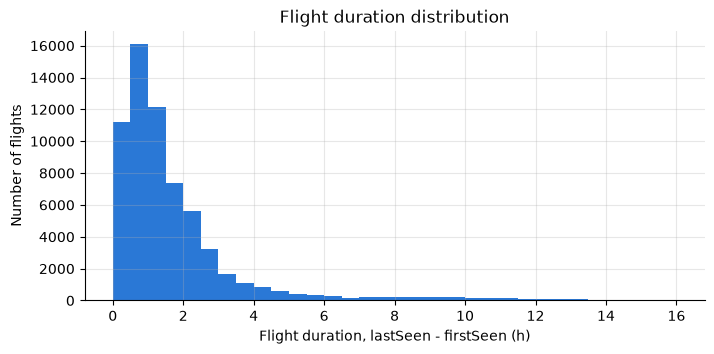

In [5]:
valid_flights = flights.dropna(
    subset=["firstSeen", "estDepartureAirport", "estArrivalAirport"]
).copy()
valid_flights["duration_min"] = (valid_flights["lastSeen"] - valid_flights["firstSeen"]) / 60
print(f"{len(valid_flights):,} flights kept ({len(valid_flights) / len(flights):.0%})")

# Time window of the flights with respect to the downloaded day
day_start = coverage["start"].min().normalize().timestamp()
print(f"lastSeen: from {to_utc(valid_flights['lastSeen'].min())} to {to_utc(valid_flights['lastSeen'].max())}")
print(f"Flights that started before the day: "
      f"{(valid_flights['firstSeen'] < day_start).mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(valid_flights["duration_min"] / 60, bins=np.arange(0, 16.5, 0.5))
ax.set_xlabel("Flight duration, lastSeen - firstSeen (h)")
ax.set_ylabel("Number of flights")
ax.set_title("Flight duration distribution")
plt.show()

**Takeaway.** The flights table contains the flights that *ended* during the day; some of them started the day before, so their first hours have no state vectors in our data. Long-haul flights are therefore under-represented: this is a known limitation of working on a single day.

## 2. Matching state vectors to flights

State vectors have no flight identifier: they only carry the aircraft (`icao24`). An aircraft flies several times a day, so a state vector belongs to the flight of the same aircraft whose time window contains it:

`sv.icao24 == flight.icao24` and `flight.firstSeen <= sv.time <= flight.lastSeen`

This only works if the flights of a given aircraft never overlap. Let's check it.

In [6]:
flights_lookup = make_flights_lookup(flights)  # the valid flights, sorted by aircraft and time
same_aircraft = flights_lookup["icao24"].eq(flights_lookup["icao24"].shift())
overlapping = same_aircraft & (flights_lookup["firstSeen"] <= flights_lookup["lastSeen"].shift())

print(f"{len(flights_lookup):,} flights, {flights_lookup['icao24'].nunique():,} aircraft")
print(f"Duplicated flight keys: {flights_lookup.duplicated(FLIGHT_KEY).sum()}")
print(f"Overlapping flights of the same aircraft: {overlapping.sum()}")

63,785 flights, 29,443 aircraft
Duplicated flight keys: 0
Overlapping flights of the same aircraft: 0


The flight key `(icao24, firstSeen, lastSeen)` is unique and flights never overlap, so each state vector matches at most one flight.

For each hourly file, only the flights overlapping that hour are candidates, which keeps the join small. We also:
- keep airborne points only (`onGround == False`): we want to predict the remaining time of a flight in the air;
- drop rows with missing values;
- compute a first version of the label, `remaining_time = lastSeen - time` (refined in section 6).

In [7]:
# The processing is in src/opensky_eta/dataset.py, also run by `python -m opensky_eta.dataset`
summary = match_state_vectors(flights_lookup, n_files=N_FILES)  # writes matched/
print(f"{summary['rows read'].sum():,} rows read, {summary['rows matched'].sum():,} matched "
      f"({summary['rows matched'].sum() / summary['rows read'].sum():.0%})")
display(summary)

695,706,186 rows read, 296,324,548 matched (43%)


,hour,candidate flights,rows read,rows matched
4,2026-03-01 00:00:00+00:00,8625,26697144,15483511
23,2026-03-01 01:00:00+00:00,7845,24538301,14125981
14,2026-03-01 02:00:00+00:00,7044,21954174,12420355
17,2026-03-01 03:00:00+00:00,6293,19968774,10796826
21,2026-03-01 04:00:01+00:00,5465,17958204,8984915
8,2026-03-01 05:00:01+00:00,4933,17011846,7757880
3,2026-03-01 06:00:00+00:00,4751,17782769,8098911
7,2026-03-01 07:00:00+00:00,4649,18056644,8065375
9,2026-03-01 08:00:00+00:00,4642,18657442,8107777
16,2026-03-01 09:00:00+00:00,4818,19784304,8482478


A quick look at the matched data: flights, points per flight and the distribution of the (first) label.

296,324,548 state vectors, 63,329 flights


,count,mean,std,min,25%,50%,75%,max
points per flight,63329.0,4679.0,3649.0,1.0,2092.0,3709.0,6274.0,37858.0


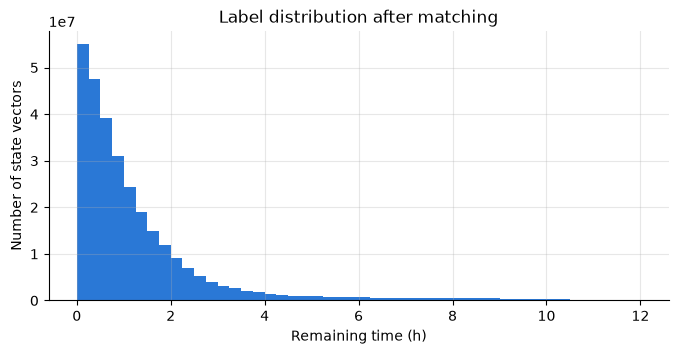

In [8]:
flight_stats_matched = compute_flight_stats(MATCHED_DIR, N_FILES)
print(f"{flight_stats_matched['n_points'].sum():,} state vectors, {len(flight_stats_matched):,} flights")
display(flight_stats_matched["n_points"].describe().round(0).to_frame("points per flight").T)

remaining_time = pd.concat(
    [pd.read_parquet(path, columns=["remaining_time"])["remaining_time"]
     for path in list_parquet_files(MATCHED_DIR, N_FILES)]
)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(remaining_time / 3600, bins=np.arange(0, 12.25, 0.25))
ax.set_xlabel("Remaining time (h)")
ax.set_ylabel("Number of state vectors")
ax.set_title("Label distribution after matching")
plt.show()
del remaining_time

**Takeaway.** The unmatched rows are aircraft on the ground, rows with missing values (mostly no position), or flights without estimated airports. The number of points per flight is very uneven (from a handful to tens of thousands): some flights are fragments or local flights, and long flights dominate the point count. Both issues are dealt with later (flight selection in section 4, balanced sampling in section 6).

## 3. Altitude data quality and cleaning

Altitude is the most informative variable to locate a flight in its climb / cruise / descent cycle, so it has to be reliable. The state vectors carry two altitudes:
- `baroAltitude`: pressure altitude, the one used by air traffic control (flight levels);
- `geoAltitude`: geometric (GNSS) altitude.

### 3.1 Symptoms

One point per flight: max altitude vs cruise speed (max velocity at the max altitude).

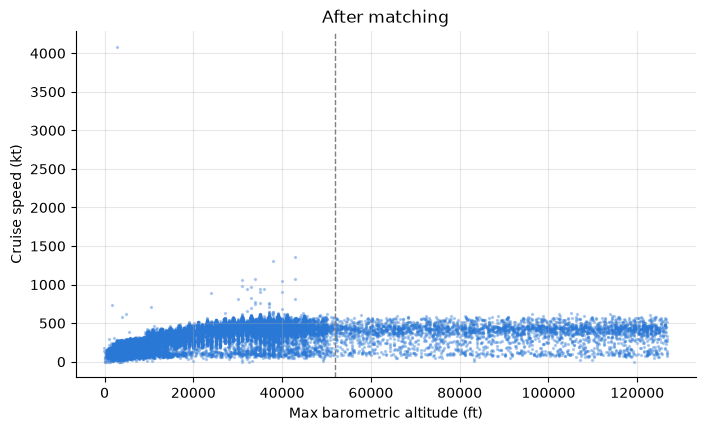

Flights above 52,000 ft: 3,118 (4.9%), up to 126,800 ft


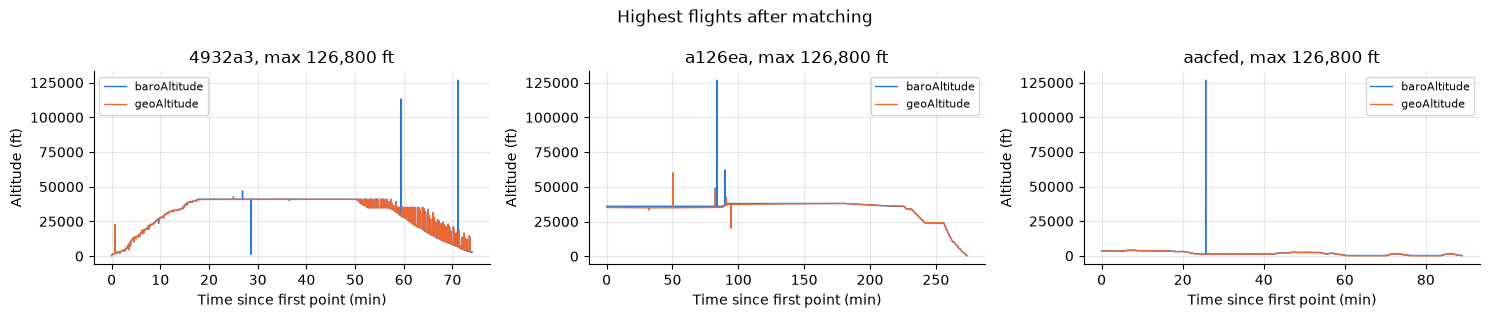

In [9]:
if "flight_stats_matched" not in globals():  # when starting the notebook at this section
    flight_stats_matched = compute_flight_stats(MATCHED_DIR, N_FILES)

fig, ax = plt.subplots(figsize=(8, 4.5))
plot_altitude_vs_speed(flight_stats_matched, ax, "After matching")
ax.axvline(ALTITUDE_CEILING_FT, color="gray", linestyle="--", linewidth=1)
plt.show()

above_ceiling = flight_stats_matched["max_altitude_ft"] > ALTITUDE_CEILING_FT
print(f"Flights above {ALTITUDE_CEILING_FT:,} ft: {above_ceiling.sum():,} "
      f"({above_ceiling.mean():.1%}), up to {flight_stats_matched['max_altitude_ft'].max():,.0f} ft")

highest_flights = flight_stats_matched.nlargest(3, "max_altitude_ft")
plot_altitude_profiles(MATCHED_DIR, highest_flights, columns=("baroAltitude", "geoAltitude"),
                       title="Highest flights after matching")

No aircraft flies above ~51,000 ft (the ceiling of the highest business jets), yet some flights reach more than 100,000 ft. The profiles show that the errors are **isolated spikes or short plateaus**, not whole flights: the rest of each trajectory looks normal.

### 3.2 Diagnosis

Three questions, answered on one hourly file:
1. Is a threshold on the apparent vertical speed (Δh / Δt between two consecutive points) a good way to catch these errors?
2. How far apart are the two altitudes normally?
3. Which altitude should be the reference for the rest of the pipeline?

In [10]:
sample = (
    pd.read_parquet(list_parquet_files(MATCHED_DIR, N_FILES)[0],
                    columns=FLIGHT_KEY + ["time", "baroAltitude", "geoAltitude", "vertRate"])
    .sort_values(FLIGHT_KEY + ["time"])
    .reset_index(drop=True)
)
same_flight = sample[FLIGHT_KEY].eq(sample[FLIGHT_KEY].shift()).all(axis=1)
time_step_s = sample["time"].diff()

diagnosis = {}
for column in ["baroAltitude", "geoAltitude"]:
    altitude_ft = sample[column] * M_TO_FT
    step_ft = altitude_ft.diff().where(same_flight)
    fast = (step_ft / time_step_s * 60).abs() > MAX_APPARENT_VZ_FT_MIN
    diagnosis[column] = {
        f"points above {ALTITUDE_CEILING_FT:,} ft": (altitude_ft > ALTITUDE_CEILING_FT).sum(),
        f"apparent |Vz| > {MAX_APPARENT_VZ_FT_MIN:,} ft/min": fast.sum(),
        f"... with a step < {MIN_JUMP_FT:,} ft": (fast & (step_ft.abs() < MIN_JUMP_FT)).sum(),
        "... right after an unchanged value": (fast & step_ft.shift().eq(0)).sum(),
    }
display(pd.DataFrame(diagnosis))

gap_ft = (sample["baroAltitude"] - sample["geoAltitude"]) * M_TO_FT
display(gap_ft.quantile([0.001, 0.01, 0.5, 0.99, 0.999]).round(0)
        .rename("baroAltitude - geoAltitude (ft)").to_frame().T)

,baroAltitude,geoAltitude
"points above 52,000 ft",95,113
"apparent |Vz| > 7,500 ft/min",12685,19161
"... with a step < 1,000 ft",11569,17653
... right after an unchanged value,11568,13948


,0.001,0.010,0.500,0.990,0.999
baroAltitude - geoAltitude (ft),-2550.0,-1650.0,-150.0,825.0,1650.0


1. **The apparent vertical speed is a poor criterion.** Most of the "impossible" vertical speeds are small steps coming right after an unchanged value: the altitude was repeated for a few seconds (stale value, see section 1.1), then caught up in one step. Conversely, a multi-second plateau at a wrong altitude is only caught at its first point. A better criterion compares each point with its neighbours: **the distance to the rolling median** of the flight.
2. **Baro and geo normally stay within ~2,000 ft of each other** (see the quantiles above). A much larger gap means that one of them is wrong: this gives a simple **cross-check**.
3. **Which reference altitude?** Let's look at a flight in cruise.

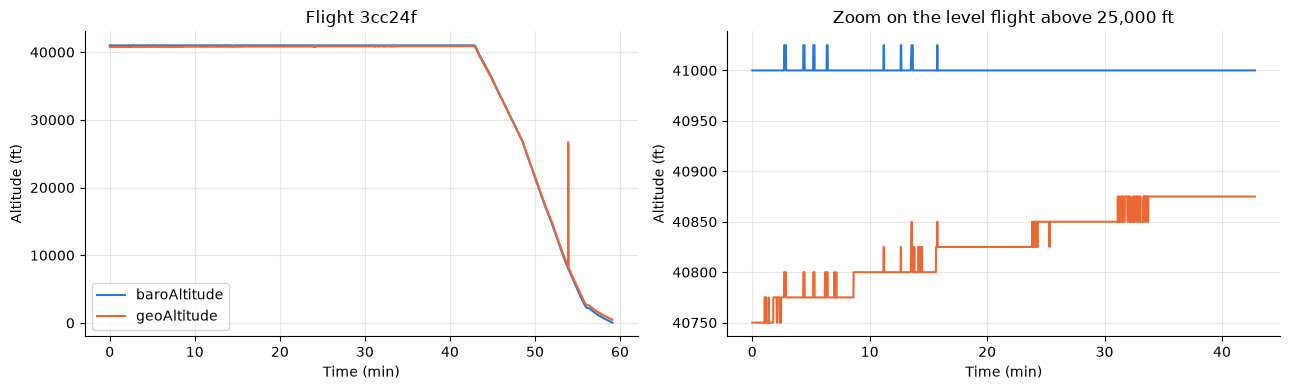

In [11]:
# Flight with the longest level flight above 25,000 ft in this file
in_cruise = ((sample["vertRate"] * MS_TO_FT_MIN).abs() < LEVEL_VZ_FT_MIN) & (
    sample["baroAltitude"] * M_TO_FT > 25_000
)
example_key = sample[in_cruise].groupby(FLIGHT_KEY).size().idxmax()
example = sample[sample[FLIGHT_KEY].eq(pd.Series(example_key, index=FLIGHT_KEY)).all(axis=1)]
minutes = (example["time"] - example["time"].iloc[0]) / 60
cruise = example[in_cruise.loc[example.index]]  # mask aligned on the rows of the example
cruise_minutes = (cruise["time"] - example["time"].iloc[0]) / 60

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, x, data in [(axes[0], minutes, example), (axes[1], cruise_minutes, cruise)]:
    ax.plot(x, data["baroAltitude"] * M_TO_FT, label="baroAltitude")
    ax.plot(x, data["geoAltitude"] * M_TO_FT, label="geoAltitude")
    ax.set_xlabel("Time (min)")
    ax.set_ylabel("Altitude (ft)")
axes[0].set_title(f"Flight {example_key[0]}")
axes[1].set_title("Zoom on the level flight above 25,000 ft")
axes[0].legend()
plt.tight_layout()
plt.show()
del sample, example, cruise

In cruise, the barometric altitude stays exactly on the flight level while the geometric altitude drifts by more than a hundred feet (it depends on the temperature along the route). Flight levels are pressure altitudes, so **`baroAltitude` is the reference altitude from now on**: it is used to detect the cruise level (section 5) and in the flight statistics. `geoAltitude` is kept as a feature and for the cross-check.

**Other variables.** Speed and vertical rate are not affected by the altitude errors, but they may have their own outliers. Extreme quantiles on the same hourly file:

In [12]:
sample = pd.read_parquet(
    list_parquet_files(MATCHED_DIR, N_FILES)[0],
    columns=["velocity", "vertRate", "baroAltitude", "geoAltitude"],
)
extremes = pd.DataFrame({
    "speed (kt)": sample["velocity"] * MS_TO_KT,
    "|vertical rate| (ft/min)": sample["vertRate"].abs() * MS_TO_FT_MIN,
    "baroAltitude (ft)": sample["baroAltitude"] * M_TO_FT,
    "geoAltitude (ft)": sample["geoAltitude"] * M_TO_FT,
})
display(extremes.quantile([0, 0.0001, 0.5, 0.9999, 1]).round(0)
        .rename_axis("quantile"))

bounds = {
    f"speed > {MAX_SPEED_KT} kt": extremes["speed (kt)"] > MAX_SPEED_KT,
    f"|vertical rate| > {MAX_VERTICAL_RATE_FT_MIN:,} ft/min":
        extremes["|vertical rate| (ft/min)"] > MAX_VERTICAL_RATE_FT_MIN,
    f"altitude < {MIN_ALTITUDE_FT:,} ft":
        extremes[["baroAltitude (ft)", "geoAltitude (ft)"]].min(axis=1) < MIN_ALTITUDE_FT,
}
display(pd.Series({name: mask.sum() for name, mask in bounds.items()}, name="points").to_frame())
del sample, extremes, bounds

,speed (kt),|vertical rate| (ft/min),baroAltitude (ft),geoAltitude (ft)
quantile,,,,
0.0000,0.0,0.0,-3025.0,-1850.0
0.0001,0.0,0.0,-375.0,-75.0
0.5000,207.0,320.0,6125.0,6225.0
0.9999,774.0,7232.0,45000.0,46375.0
1.0000,1943.0,32640.0,125200.0,125475.0


,points
speed > 750 kt,1093
"|vertical rate| > 10,000 ft/min",368
"altitude < -1,500 ft",3


The median values are realistic, but the extremes are physically impossible: nearly 2,000 knots, 32,640 ft/min (a saturated value), altitudes thousands of feet below sea level. These measurement errors are removed with generous physical bounds, which leave every plausible point untouched:
- speed ≤ 750 kt (with a strong jet stream, the fastest airliners reach ~700 kt of ground speed);
- |vertical rate| ≤ 10,000 ft/min (airliners rarely exceed 6,000 ft/min);
- altitude between −1,500 ft (the lowest airport is ~1,300 ft below sea level, and the pressure altitude can be a few hundred feet negative on high-pressure days) and 52,000 ft.

### 3.3 Cleaning

A point is removed if:
1. **Spike:** its `baroAltitude` or its `geoAltitude` is more than 1,000 ft away from the rolling median of the 31 surrounding points of the same flight (~30 s). During a regular climb or descent the median follows the trajectory, while a spike or a plateau shorter than ~15 s stands out.
2. **Inconsistency:** |baroAltitude − geoAltitude| > 5,000 ft.
3. **Offset segment:** it lies in a longer segment shifted from the rest of the flight. Such a segment starts and ends with a *jump*, i.e. a step larger than 1,000 ft that the reported vertical rate (`vertRate`) cannot explain. Two jumps delimit a segment only if the second one roughly cancels the first one and they are less than 5 minutes apart. The segment is then removed if it deviates by more than 5,000 ft from the straight line joining its neighbours.
4. **Impossible value:** speed > 750 kt, |vertical rate| > 10,000 ft/min, or an altitude outside [−1,500 ft, 52,000 ft].

The last two constraints matter: without them, two unrelated jumps far apart in time could be paired, and a whole valid descent deleted.

Implementation: each file is sorted by flight and time *through an index* (the table itself is never sorted, to keep the memory low), and the result is written back batch by batch.

In [13]:
# The processing is in src/opensky_eta/dataset.py, also run by `python -m opensky_eta.dataset`
summary = clean_state_vectors(n_files=N_FILES)  # writes clean/
total = summary.sum(numeric_only=True)
print(f"Removed {total['removed']:,} of {total['rows']:,} state vectors "
      f"({total['removed'] / total['rows']:.2%}); a point can be counted in several columns")
display(summary)

Removed 1,981,199 of 296,324,548 state vectors (0.67%); a point can be counted in several columns


,file,rows,spikes,inconsistent,impossible,offset segments,removed
0,06db1353,6835819,980,4775,1483,19,6002
1,229792d1,14979200,120321,11771,2096,13387,137048
2,29422461,18661095,38205,16530,2336,6008,59202
3,36e1108c,8098911,4461,15822,498,457,19524
4,3d627b04,15483511,1950,6595,1676,255,9189
5,3fb30eb6,15680870,154993,16264,2269,70724,234304
6,4295aede,15853118,3150,16205,1299,197,18705
7,43971b16,8065375,7562,9201,195,254,15646
8,468a81ff,7757880,1466,44965,3421,670,49245
9,470be778,8107777,12829,8381,758,154,20205


### 3.4 Result

Same views as in 3.1, after cleaning.

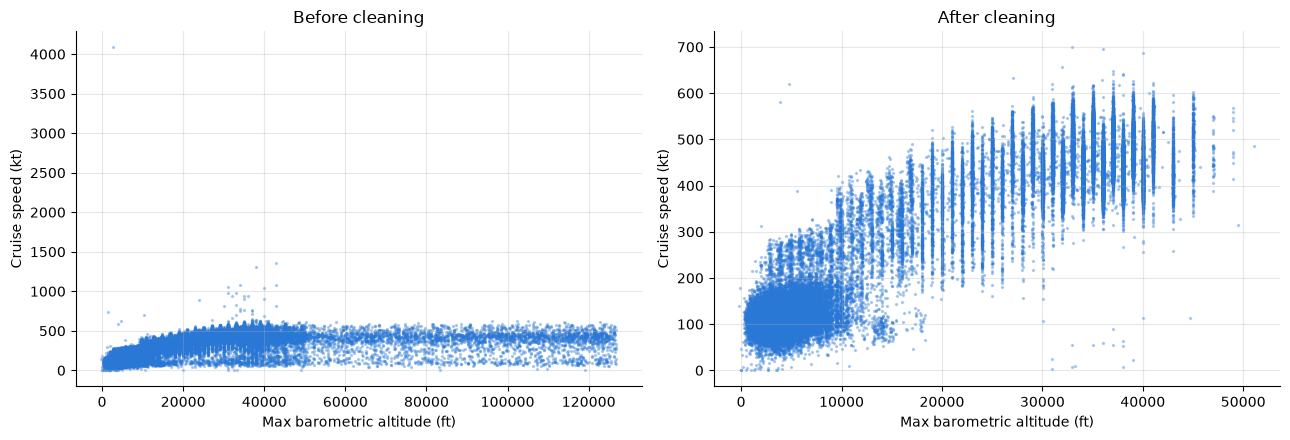

,flights,"flights above 52,000 ft",highest altitude (ft)
before cleaning,63329,3118,126800.0
after cleaning,63328,0,51100.0


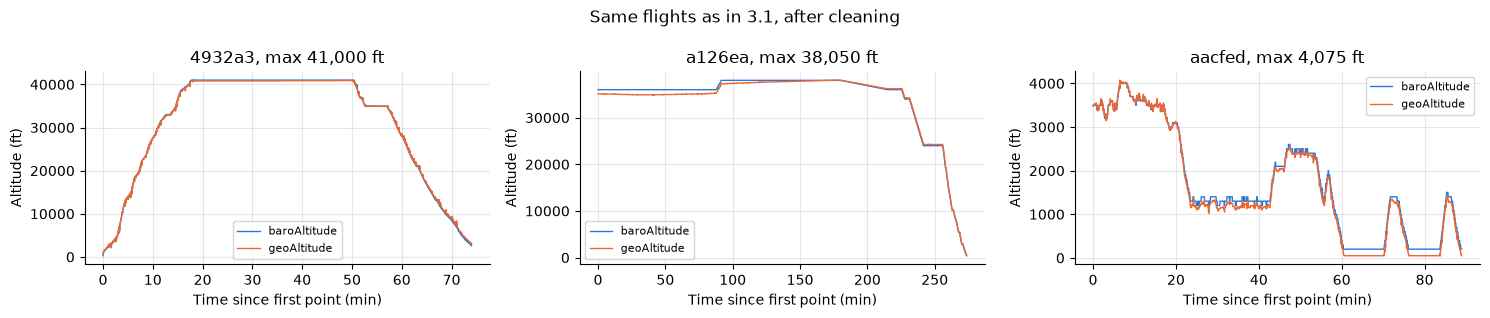

In [14]:
flight_stats_clean = compute_flight_stats(CLEAN_DIR, N_FILES)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_altitude_vs_speed(flight_stats_matched, axes[0], "Before cleaning")
plot_altitude_vs_speed(flight_stats_clean, axes[1], "After cleaning")
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "flights": [len(flight_stats_matched), len(flight_stats_clean)],
    f"flights above {ALTITUDE_CEILING_FT:,} ft": [
        (stats["max_altitude_ft"] > ALTITUDE_CEILING_FT).sum()
        for stats in (flight_stats_matched, flight_stats_clean)
    ],
    "highest altitude (ft)": [
        stats["max_altitude_ft"].max().round() for stats in (flight_stats_matched, flight_stats_clean)
    ],
}, index=["before cleaning", "after cleaning"]))

plot_altitude_profiles(CLEAN_DIR, highest_flights, columns=("baroAltitude", "geoAltitude"),
                       title="Same flights as in 3.1, after cleaning")

**Takeaway.** Less than 1 % of the points are removed, and no impossible altitude, speed or vertical rate is left. The remaining flights around 45,000–51,000 ft are real: business jets cruise that high.

A known limitation remains: some flights contain *replayed* old state vectors (an old position and altitude inserted among the current ones). The cleaning removes most of them but not all; the `lastPosUpdate` column of the raw data would be needed to filter them properly.

## 4. Selecting commercial (IFR) flights

The project targets airliner-like flights (instrument flight rules), but the data also contains light aircraft, helicopters, gliders or training flights. The clean flight statistics show two populations:

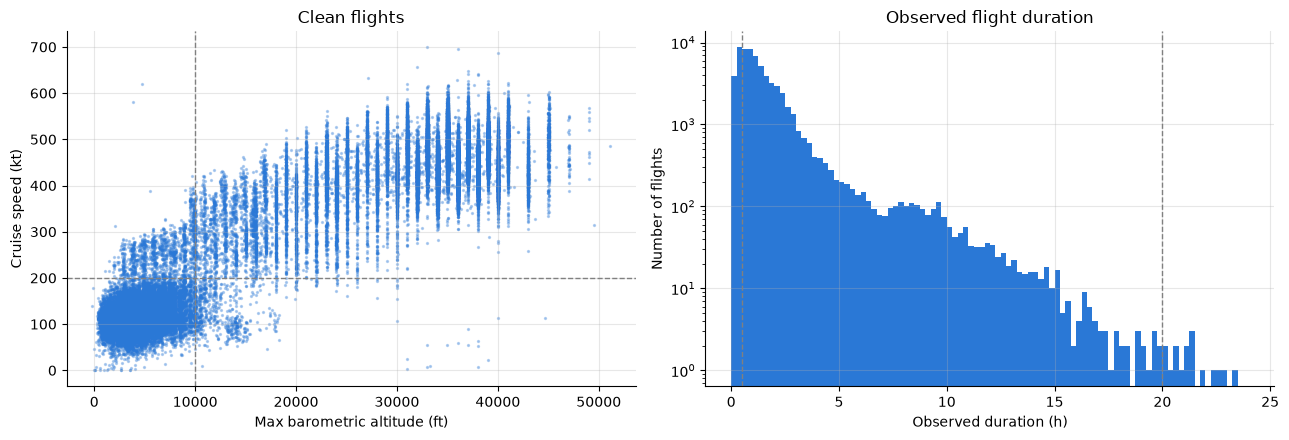

In [15]:
if "flight_stats_clean" not in globals():  # when starting the notebook at this section
    flight_stats_clean = compute_flight_stats(CLEAN_DIR, N_FILES)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_altitude_vs_speed(flight_stats_clean, axes[0], "Clean flights")
axes[0].axvline(MIN_MAX_ALTITUDE_FT, color="gray", linestyle="--", linewidth=1)
axes[0].axhline(MIN_CRUISE_SPEED_KT, color="gray", linestyle="--", linewidth=1)

axes[1].hist(flight_stats_clean["duration_min"] / 60, bins=np.arange(0, 24.25, 0.25))
axes[1].axvline(MIN_DURATION_MIN / 60, color="gray", linestyle="--", linewidth=1)
axes[1].axvline(MAX_DURATION_H, color="gray", linestyle="--", linewidth=1)
axes[1].set_yscale("log")
axes[1].set_xlabel("Observed duration (h)")
axes[1].set_ylabel("Number of flights")
axes[1].set_title("Observed flight duration")
plt.tight_layout()
plt.show()

Airliners cluster above ~25,000 ft and ~350 kt, while light aircraft stay low and slow. A flight is kept if it:
- reaches at least **10,000 ft** (barometric);
- has a cruise speed of at least **200 kt**;
- is observed for at least **30 min** (shorter flights leave too little to predict);
- is observed for at most **20 h**: the longest scheduled flights last ~19 h, so longer records are tracking artefacts.

In [16]:
# The processing is in src/opensky_eta/dataset.py, also run by `python -m opensky_eta.dataset`
criteria = ifr_criteria(flight_stats_clean)
is_ifr = ~criteria.any(axis=1)
display(pd.DataFrame({"flights failing": criteria.sum(), "share": criteria.mean().round(3)}))
print(f"Kept: {is_ifr.sum():,} of {len(is_ifr):,} flights ({is_ifr.mean():.0%}); "
      f"a flight can fail several criteria")

n_before, n_after = write_ifr_flights(flight_stats_clean.loc[is_ifr, FLIGHT_KEY], n_files=N_FILES)  # writes ifr/
print(f"State vectors: {n_before:,} -> {n_after:,} ({n_after / n_before:.0%} kept)")

,flights failing,share
"max altitude < 10,000 ft",22806,0.360
cruise speed < 200 kt,22151,0.350
observed duration < 30 min,12569,0.198
observed duration > 20 h,16,0.000


Kept: 38,025 of 63,328 flights (60%); a flight can fail several criteria


State vectors: 294,343,349 -> 233,520,393 (79% kept)


Distributions of the label, the altitude and the vertical rate on the selected flights:

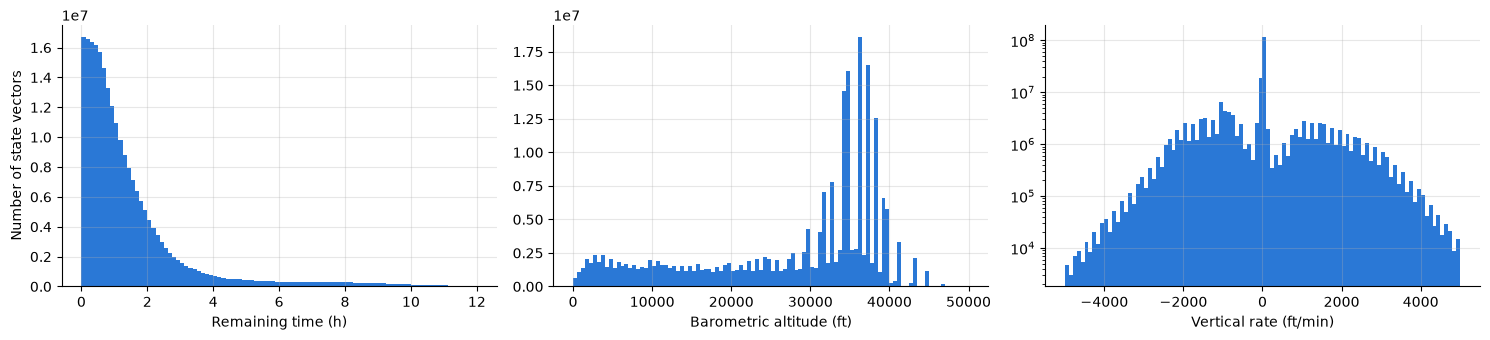

In [17]:
histograms = {
    "remaining_time": (np.linspace(0, 12, 97), 1 / 3600, "Remaining time (h)"),
    "baroAltitude": (np.linspace(0, 50_000, 101), M_TO_FT, "Barometric altitude (ft)"),
    "vertRate": (np.linspace(-5_000, 5_000, 101), MS_TO_FT_MIN, "Vertical rate (ft/min)"),
}
counts = {column: np.zeros(len(edges) - 1, dtype=np.int64)
          for column, (edges, _, _) in histograms.items()}
for path in list_parquet_files(IFR_DIR, N_FILES):
    df = pd.read_parquet(path, columns=list(histograms))
    for column, (edges, scale, _) in histograms.items():
        counts[column] += np.histogram(df[column].to_numpy() * scale, bins=edges)[0]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, (column, (edges, _, label)) in zip(axes, histograms.items()):
    ax.stairs(counts[column], edges, fill=True)
    ax.set_xlabel(label)
axes[0].set_ylabel("Number of state vectors")
axes[2].set_yscale("log")
plt.tight_layout()
plt.show()

**Takeaway.** About 60 % of the flights and 80 % of the state vectors are kept: the removed flights are numerous but short. The altitude distribution peaks at typical cruise levels (35,000–40,000 ft) and the vertical rate is dominated by level flight: cruise points largely outnumber climb and descent points, which the sampling will have to rebalance.

## 5. Flight phases

The selected flights still contain ~230M state vectors, far more than needed, and very unevenly distributed (long cruises dominate). To build a balanced dataset (section 6), we need to know where each point lies in its flight: **climb, cruise or descent**.

The chosen approach is to find the **cruise** first (the longest and most stable part of a flight); everything before it is climb, everything after it is descent. Three passes over the data:

1. **Cruise level.** Keep the level-flight points (|vertical rate| < 200 ft/min) and build, for each flight, a histogram of their barometric altitude with 500 ft bins centred on multiples of 500 ft (so that a flight level such as FL350 = 35,000 ft falls in the middle of a bin). The most populated bin is the cruise level; the cruise band is this level ± 500 ft (neighbouring flight levels are 1,000 ft apart, so they fall outside).
2. **Cruise window.** The first and last times the aircraft is inside the cruise band.
3. **Classification.** Each point is labelled by its time relative to the window:

| Position | Vertical rate | Phase |
|---|---|---|
| before the window | > +200 ft/min | `climb` |
| before the window | otherwise | `est_climb` (level-off during the climb) |
| inside the window | any | `cruise` (window > 10 min) or `short cruise` |
| after the window | < −200 ft/min | `descent` |
| after the window | otherwise | `est_descent` (level-off, holding pattern) |

Inside the window, the time decides, not the altitude: step climbs during the cruise (e.g. FL340 → FL360) remain `cruise`.

**Warning:** `phase_of_flight` uses the whole flight, including its future (the end of the cruise window is only known once the flight is over). It is a **sampling tool, not a feature**: using it as a model input would leak the label. Notebooks 04 and 05 use it under an explicit assumption (a phase of flight known at any time, e.g. from the flight plan); the selected gradient boosting does not use it.

In [18]:
# The processing is in src/opensky_eta/dataset.py, also run by `python -m opensky_eta.dataset`
cruise_info, phase_counts, n_flights = label_phases(n_files=N_FILES)  # writes cruise_info.parquet and phases/
print(f"Cruise identified for {len(cruise_info):,} of {n_flights:,} flights")
display(pd.DataFrame({
    "state vectors": phase_counts.sum(),
    "share": (phase_counts.sum() / phase_counts.sum().sum()).round(3),
    "flights with this phase": (phase_counts > 0).sum(),
}))

Cruise identified for 38,013 of 38,025 flights


,state vectors,share,flights with this phase
phase_of_flight,,,
climb,36275546,0.155,35733
est_climb,10585006,0.045,22090
cruise,121959706,0.522,34595
short cruise,1452538,0.006,3418
descent,49934839,0.214,37941
est_descent,13291828,0.057,35049


What the classification looks like on a typical flight (the grey band is the detected cruise band):

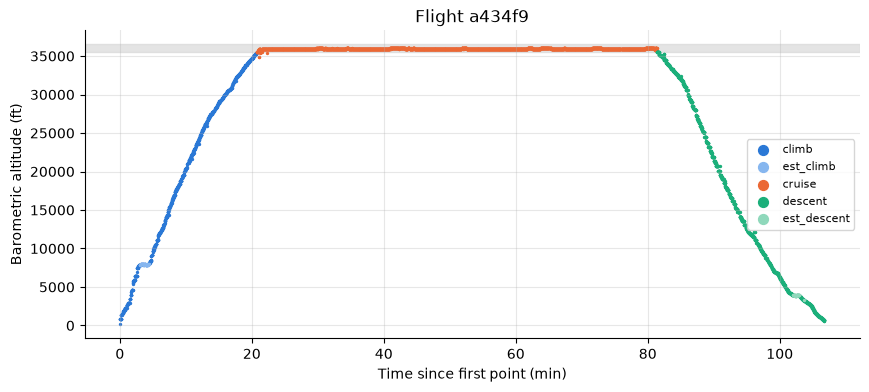

In [19]:
cruise_by_flight = cruise_info.set_index(FLIGHT_KEY)


def plot_flight_phases(flight, ax):
    """Barometric altitude of one flight, coloured by phase, with its cruise band."""
    trajectory = read_flight(PHASES_DIR, flight, ["time", "baroAltitude", "phase_of_flight"])
    minutes = (trajectory["time"] - trajectory["time"].iloc[0]) / 60
    info = cruise_by_flight.loc[tuple(flight[FLIGHT_KEY])]
    ax.axhspan(info["cruise_lower_ft"], info["cruise_upper_ft"], color="lightgray", alpha=0.6)
    for phase, color in PHASE_COLORS.items():
        points = trajectory["phase_of_flight"] == phase
        if points.any():
            ax.scatter(minutes[points], trajectory.loc[points, "baroAltitude"] * M_TO_FT,
                       s=2, color=color, label=phase)
    ax.set_xlabel("Time since first point (min)")
    ax.set_ylabel("Barometric altitude (ft)")
    ax.legend(markerscale=5, fontsize=8)


# A flight with every phase except short cruise, of median size
complete = phase_counts[(phase_counts.drop(columns="short cruise") > 0).all(axis=1)]
total_points = complete.sum(axis=1)
typical_key = (total_points - total_points.median()).abs().idxmin()

fig, ax = plt.subplots(figsize=(10, 4))
plot_flight_phases(pd.Series(typical_key, index=FLIGHT_KEY), ax)
ax.set_title(f"Flight {typical_key[0]}")
plt.show()

**When the cruise is not observed.** The cruise can be missing from the data: the flight started before the downloaded day (only its descent is there), or it crossed an ocean without ADS-B coverage. The most populated level is then a level-off during the approach, and every phase of the flight is wrong. These flights are easy to spot: their "cruise" level is far below their maximum altitude.

1,072 flights (2.8%) have a cruise level more than 5,000 ft below their max altitude


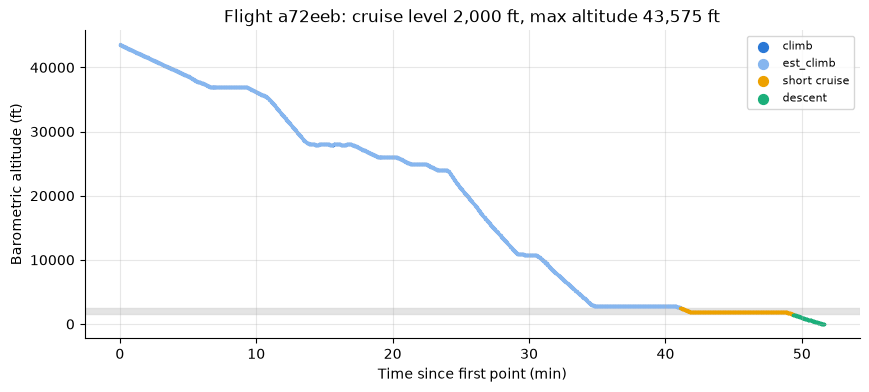

In [20]:
cruise_gap_ft = cruise_info["max_altitude_ft"] - cruise_info["cruise_altitude_ft"]
suspicious = cruise_gap_ft > MAX_CRUISE_GAP_FT
print(f"{suspicious.sum():,} flights ({suspicious.mean():.1%}) have a cruise level more than "
      f"{MAX_CRUISE_GAP_FT:,} ft below their max altitude")

worst = cruise_info.loc[cruise_gap_ft.idxmax()]
fig, ax = plt.subplots(figsize=(10, 4))
plot_flight_phases(worst, ax)
ax.set_title(f"Flight {worst['icao24']}: cruise level {worst['cruise_altitude_ft']:,.0f} ft, "
             f"max altitude {worst['max_altitude_ft']:,.0f} ft")
plt.show()

**Takeaway.** A cruise is identified for almost every flight. About 10 % of the points are `est_*`: level-offs during the climb or the descent, or a lower level flown after the main cruise. The flights whose cruise level is far below their max altitude are excluded in the next section.

## 6. Building the ML dataset

**Why sample?** Consecutive state vectors of a flight (one per second) are almost identical, so keeping all of them would add little information, give long flights a much larger weight and produce an unmanageable dataset. We keep a fixed number of points per flight, **15 before the cruise, 30 in cruise and 15 after the cruise**, which gives every flight the same weight and over-represents climb and descent compared to their duration (they are where the remaining time is hardest to predict). With ~35,000 flights, this gives ~2M state vectors.

**Segments.** The phases are grouped into three segments: `pre` = climb + est_climb, `cruise` = cruise + short cruise, `post` = descent + est_descent. The `est_*` phases are kept on purpose: level-offs and holding patterns happen in real life, and the model must see them.

**Sampling by rank.** In a segment of `c` observed points sorted in time, we take the points of rank `floor((k + 0.5) * c / N)` for `k = 0 … N-1`: N points evenly spread *among the observed points*. A first version spread the points evenly *in time* and looked for the nearest observed point: with coverage gaps, several targets fell on the same point and the flight had to be dropped. Sampling by rank always gives exactly N distinct points, and follows the real use case: a prediction can only be made where there is data.

**Eligibility.** A flight is kept if every segment has enough points and if its cruise level is at most 5,000 ft below its max altitude (see section 5).

**Final label.** `remaining_time = last_airborne_time - time`, where `last_airborne_time` is the time of the last airborne state vector of the flight. The first label (`lastSeen - time`) is kept as `remaining_time_lastseen` for comparison.

Ranks must be counted in time order across the hourly files: the files are processed in chronological order (they do not overlap).

In [21]:
# The processing is in src/opensky_eta/dataset.py, also run by `python -m opensky_eta.dataset`
df_ml, report = sample_ml_dataset(n_files=N_FILES)  # writes ml/ml_dataset.parquet
display(report["eligibility"].to_frame())
print(f"{report['share with coverage gaps']:.0%} of the selected flights have "
      f"a segment with more than 10 % of missing seconds (coverage gaps)")

# Checks
display(check_ml_dataset(df_ml).to_frame())
label_gap_min = (
    df_ml.groupby(FLIGHT_KEY)[["lastSeen", "last_airborne_time"]].first()
    .pipe(lambda d: (d["lastSeen"] - d["last_airborne_time"]) / 60)
)
print(f"lastSeen - last airborne time: median {label_gap_min.median():.1f} min, "
      f"mean {label_gap_min.mean():.2f} min, max {label_gap_min.max():.0f} min")
print(f"Saved {ML_DATASET_PATH.relative_to(PROJECT_DIR)}: {df_ml.shape}")

,flights
flights with phases,38013
enough points in every segment,35987
... and consistent cruise level,35027


20% of the selected flights have a segment with more than 10 % of missing seconds (coverage gaps)


,value
flights,35027
state vectors,2101620
flights with exactly 15 / 30 / 15 points,35027
duplicated state vectors,0
missing values,0
negative labels,0
values out of physical bounds,0
"|baro - geo| > 5,000 ft",0


lastSeen - last airborne time: median 0.0 min, mean 0.05 min, max 87 min
Saved data/processed/ml/ml_dataset.parquet: (2101620, 17)


**Takeaway.** Every selected flight gives exactly 15 / 30 / 15 state vectors, with no duplicates, missing values, negative labels or physically impossible values. `lastSeen` almost always coincides with the last airborne state vector, so both labels are nearly identical; the new one has the advantage of an explicit definition.

## 7. Final dataset

In [22]:
df_ml = pd.read_parquet(ML_DATASET_PATH)
print(f"{len(df_ml):,} state vectors, {df_ml.groupby(FLIGHT_KEY).ngroups:,} flights, "
      f"{df_ml.memory_usage(deep=True).sum() / 1e6:.0f} MB in memory")
display(df_ml.head())

2,101,620 state vectors, 35,027 flights, 304 MB in memory


,time,icao24,lat,lon,velocity,heading,vertRate,baroAltitude,geoAltitude,firstSeen,lastSeen,estDepartureAirport,estArrivalAirport,remaining_time_lastseen,phase_of_flight,last_airborne_time,remaining_time
0,1772334977,0000ca,40.989532,28.859985,97.028284,56.899721,7.80288,281.94,419.10,1.772335e+09,1772341766,LTBA,LIRA,6789,climb,1772341766,6789
1,1772335071,0000ca,40.986173,28.940548,105.419605,108.788622,5.20192,777.24,701.04,1.772335e+09,1772341766,LTBA,LIRA,6695,climb,1772341766,6695
2,1772335165,0000ca,40.881570,28.866203,135.370149,223.460162,7.15264,1165.86,1143.00,1.772335e+09,1772341766,LTBA,LIRA,6601,climb,1772341766,6601
3,1772335259,0000ca,40.803772,28.748230,145.044929,260.404044,11.37920,2270.76,2331.72,1.772335e+09,1772341766,LTBA,LIRA,6507,climb,1772341766,6507
4,1772335353,0000ca,40.793726,28.583991,165.123702,265.532841,12.02944,3406.14,3451.86,1.772335e+09,1772341766,LTBA,LIRA,6413,climb,1772341766,6413


| Column | Role |
|---|---|
| `lat`, `lon`, `velocity`, `heading`, `vertRate`, `baroAltitude`, `geoAltitude` | **features** (state of the aircraft) |
| `estDepartureAirport`, `estArrivalAirport` | **features** (context known before the flight) |
| `time` | feature material (time of day), and sorting |
| `remaining_time` | **label** (seconds before the last airborne state vector) |
| `icao24`, `firstSeen`, `lastSeen` | flight identifier: use it to **split train / test by flight** |
| `phase_of_flight` | sampling tool only, **not a feature** (built with the future of the flight) |
| `last_airborne_time`, `remaining_time_lastseen`, `lastSeen` | **never features** (they contain the label) |

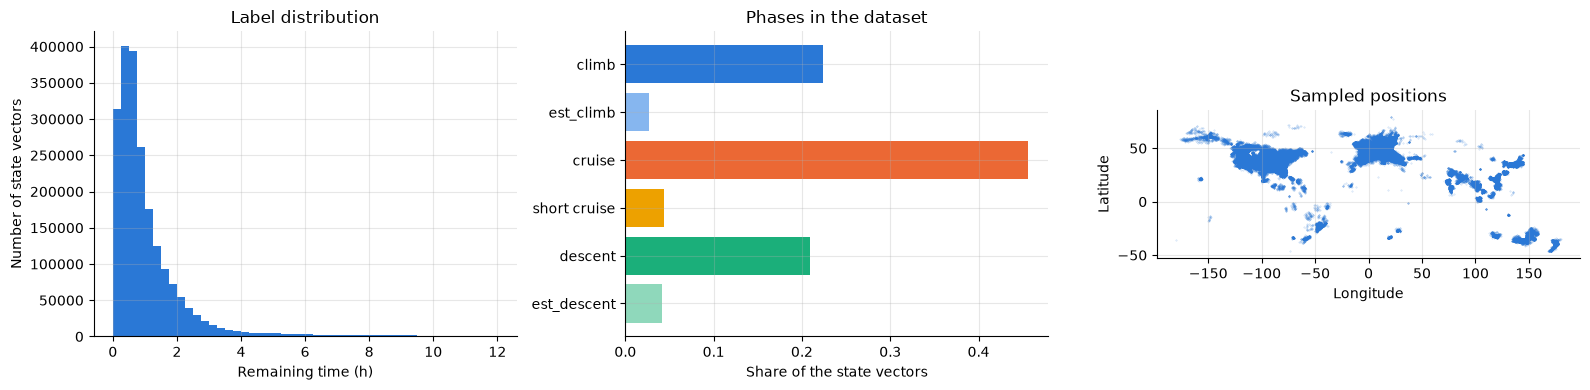

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(df_ml["remaining_time"] / 3600, bins=np.arange(0, 12.25, 0.25))
axes[0].set_xlabel("Remaining time (h)")
axes[0].set_ylabel("Number of state vectors")
axes[0].set_title("Label distribution")

phase_share = df_ml["phase_of_flight"].value_counts(normalize=True).reindex(PHASES)
axes[1].barh(phase_share.index[::-1], phase_share.values[::-1],
             color=[PHASE_COLORS[p] for p in phase_share.index[::-1]])
axes[1].set_xlabel("Share of the state vectors")
axes[1].set_title("Phases in the dataset")

positions = df_ml.sample(min(len(df_ml), 300_000), random_state=0)
axes[2].scatter(positions["lon"], positions["lat"], s=0.1, alpha=0.3)
axes[2].set_xlabel("Longitude")
axes[2].set_ylabel("Latitude")
axes[2].set_title("Sampled positions")
axes[2].set_aspect("equal")
plt.tight_layout()
plt.show()

Four random flights: the full trajectory (grey), the cruise band and the 60 selected state vectors.

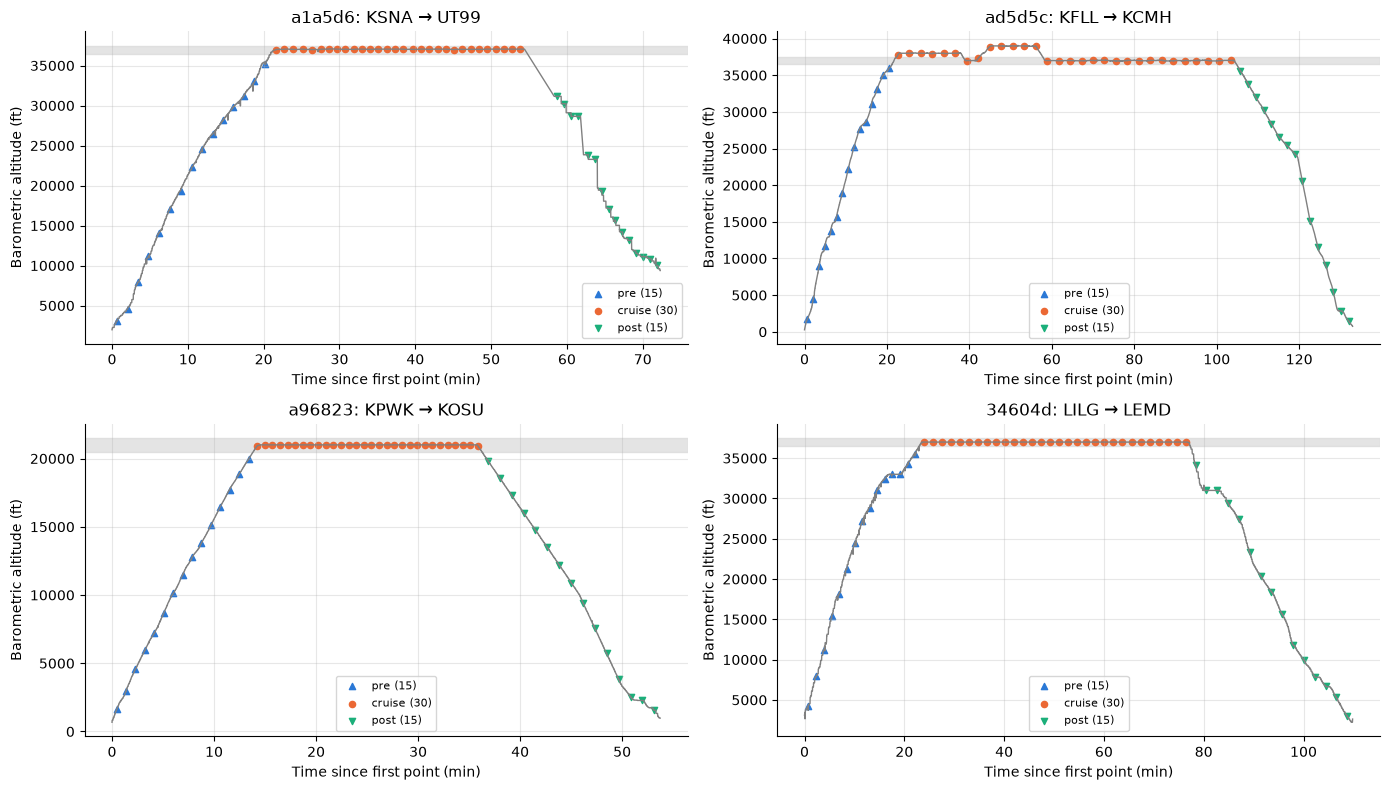

In [24]:
SEGMENT_STYLE = {"pre": ("#2a78d6", "^"), "cruise": ("#eb6834", "o"), "post": ("#1baf7a", "v")}
cruise_by_flight = pd.read_parquet(CRUISE_INFO_PATH).set_index(FLIGHT_KEY)
examples = df_ml[FLIGHT_KEY].drop_duplicates().sample(4, random_state=0)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (_, flight) in zip(axes.ravel(), examples.iterrows()):
    trajectory = read_flight(PHASES_DIR, flight, ["time", "baroAltitude"])
    t0 = trajectory["time"].iloc[0]
    info = cruise_by_flight.loc[tuple(flight)]
    ax.axhspan(info["cruise_lower_ft"], info["cruise_upper_ft"], color="lightgray", alpha=0.6)
    ax.plot((trajectory["time"] - t0) / 60, trajectory["baroAltitude"] * M_TO_FT,
            color="gray", linewidth=1)

    points = df_ml[(df_ml[FLIGHT_KEY] == flight.values).all(axis=1)]
    segment = points["phase_of_flight"].map(PHASE_TO_SEGMENT)
    for name, (color, marker) in SEGMENT_STYLE.items():
        selected_points = points[segment == name]
        ax.scatter((selected_points["time"] - t0) / 60, selected_points["baroAltitude"] * M_TO_FT,
                   s=20, color=color, marker=marker, label=f"{name} ({len(selected_points)})")
    ax.set_title(f"{flight['icao24']}: {points['estDepartureAirport'].iloc[0]} → "
                 f"{points['estArrivalAirport'].iloc[0]}")
    ax.set_xlabel("Time since first point (min)")
    ax.set_ylabel("Barometric altitude (ft)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Limitations and next steps

**Limitations of the dataset**
- **A single UTC day.** Flights that started the day before are truncated and flights landing the next day are missing, so long-haul flights are under-represented. Downloading the surrounding days would fix it.
- **Replayed state vectors.** Some flights contain old positions inserted among the current ones; filtering them properly needs the raw `lastPosUpdate` column.
- **Label.** The arrival time is the last *received* airborne state vector: when the coverage stops before the landing, the label is slightly early.
- **Processing by hourly file.** The altitude cleaning works file by file: its rolling window is cut at the hour boundaries, which affects less than 1 % of the points. Rebuilding the dataset flight by flight (all hours together) would remove this limit.

**Next steps**
- **Detect the impossible labels.** Some flight records are wrong as a whole: several flights of the same aircraft merged into one OpenSky record (the label then includes the stopover and the next flight), or a wrong estimated arrival airport. Notebooks 04 (section 6.5) and 05 (section 7.4) flag them after the fact (same departure and arrival airport, or an implied average speed far from that of the flights of the same route length): about 4 % of the flights, but more than a third of the error of every model. These checks belong in this notebook, so that the impossible labels are removed from the training and the evaluation.